# Análise de Inventário e Operação — Fulfillment Center de Marketplace

**Cenário:** atuo como analista de dados de inventário em uma rede de Fulfillment Centers (FCs) de marketplace, no modelo em que o seller envia o estoque para o FC e a plataforma armazena, separa, embala e expede os pedidos (modelo "Full" do Mercado Livre).

O inventário não é da operação, é dos sellers. Por isso a responsabilidade do time de inventário é **custódia**: garantir que o que o sistema diz que existe está fisicamente no endereço certo, que nada se perde e que o estoque gira. A operação diária precisa receber rápido, expedir no prazo e com qualidade.

> Dados **100% sintéticos**, criados para estudo. Não representam números reais de nenhuma empresa.

**Escopo:** 3 FCs (SP, MG, BA) · 620 sellers · 4.200 SKUs · jul a out/2026

| Parte | Pergunta |
|---|---|
| Qualidade de dados | A extração do WMS é confiável? Os pedidos batem com os apontamentos de produtividade? |
| A. Eficiência do inventário | O estoque está acurado? Quanto perdemos? Há estoque envelhecido? Os FCs têm espaço? A falta de acuracidade gera ruptura? |
| B. Operação diária | Recebemos rápido? Expedimos no prazo? A produtividade está na meta? Quantos pedidos saem perfeitos? |

**Stack:** Python · DuckDB (SQL) · pandas · matplotlib

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

RAW = Path("../data/raw")
con = duckdb.connect()
q = lambda sql: con.sql(sql).df()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

DATA_REF = "2026-10-31"
CORES_FC = {"SP01": "#2a78d6", "MG01": "#eb6834", "BA01": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "font.size": 10, "figure.dpi": 110,
})

def legenda_topo(ax, **kw):
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=kw.pop("ncol", 3), **kw)

## 1. Carga das extrações do WMS

Tudo lido como texto (`all_varchar`) para que nenhum problema seja mascarado pela inferência de tipos.

In [2]:
arquivos = {
    "raw_fcs": ("fcs.csv", ","), "raw_sellers": ("sellers.csv", ","), "raw_skus": ("skus.csv", ";"),
    "raw_pedidos": ("pedidos.csv.gz", ","), "raw_ocorrencias": ("ocorrencias_qualidade.csv", ","),
    "raw_recebimentos": ("recebimentos.csv", ";"), "raw_apont": ("apontamentos_produtividade.csv", ","),
    "raw_contagens": ("contagens_ciclicas.csv", ","), "raw_ajustes": ("ajustes_inventario.csv", ","),
    "raw_posicao": ("posicao_estoque.csv", ","),
}
for t, (arq, sep) in arquivos.items():
    con.execute(f"CREATE OR REPLACE TABLE {t} AS SELECT * FROM read_csv('{RAW / arq}', delim='{sep}', header=true, all_varchar=true)")

q("SELECT table_name AS tabela, estimated_size AS linhas, column_count AS colunas FROM duckdb_tables() ORDER BY 1")

,tabela,linhas,colunas
0,raw_ajustes,1049,7
1,raw_apont,3776,7
2,raw_contagens,16482,10
3,raw_fcs,3,5
4,raw_ocorrencias,735,4
5,raw_pedidos,265645,10
6,raw_posicao,9486,5
7,raw_recebimentos,8189,11
8,raw_sellers,620,4
9,raw_skus,4200,7


In [3]:
q("SELECT * FROM raw_pedidos LIMIT 6")

,order_id,fc_id,inventory_id,quantidade,dt_pedido,dt_limite_expedicao,dt_inicio_picking,dt_fim_packing,dt_expedicao,status
0,MLO2000152817,MG01,INV378512343916,4,2026-07-13 23:22:39,2026-07-14 14:00:00,2026-07-14 07:31:26,2026-07-14 08:01:06,2026-07-14 10:00:00,EXPEDIDO
1,MLO2000054242,SP01,INV631000781515,1,2026-08-16 16:49:12,2026-08-17 14:00:00,2026-08-16 16:53:12,2026-08-16 17:24:04,2026-08-16 18:00:00,EXPEDIDO
2,MLO2000233861,BA01,INV343491501159,2,10/08/2026 06:16,2026-08-10 18:00:00,2026-08-10 09:56:43,2026-08-10 10:33:53,2026-08-10 14:00:00,EXPEDIDO
3,MLO2000080510,SP01,INV752696911504,4,2026-09-08 08:46:01,2026-09-08 18:00:00,2026-09-08 10:02:15,2026-09-08 10:11:14,2026-09-08 14:00:00,EXPEDIDO
4,MLO2000116472,SP01,INV287100944034,3,2026-10-08 00:18:07,08/10/2026 18:00,2026-10-08 12:42:01,2026-10-08 13:22:58,2026-10-08 14:00:00,EXPEDIDO
5,MLO2000138518,SP01,INV987292601086,1,2026-10-26 11:16:03,2026-10-26 18:00:00,2026-10-26 11:49:36,2026-10-26 12:32:30,26/10/2026 14:00,EXPEDIDO


## 2. Diagnóstico de qualidade

In [4]:
q('''
SELECT 'pedidos: data fora do padrão ISO' AS teste, count(*) AS ocorrencias FROM raw_pedidos WHERE try_strptime(dt_pedido, '%Y-%m-%d %H:%M:%S') IS NULL
UNION ALL SELECT 'pedidos: data inválida nos dois formatos', count(*) FROM raw_pedidos
    WHERE coalesce(try_strptime(dt_pedido, '%Y-%m-%d %H:%M:%S'), try_strptime(dt_pedido, '%d/%m/%Y %H:%M')) IS NULL
UNION ALL SELECT 'pedidos: status fora do domínio', count(*) FROM raw_pedidos
    WHERE status NOT IN ('EXPEDIDO','PENDENTE','CANCELADO_FALTA_ESTOQUE','CANCELADO_CLIENTE')
UNION ALL SELECT 'pedidos: fc_id fora do padrão', count(*) FROM raw_pedidos WHERE fc_id NOT IN (SELECT fc_id FROM raw_fcs)
UNION ALL SELECT 'pedidos: inventory_id em minúsculo', count(*) FROM raw_pedidos WHERE inventory_id <> upper(inventory_id)
UNION ALL SELECT 'pedidos: order_id duplicado (linhas extras)', count(*) - count(DISTINCT order_id) FROM raw_pedidos
UNION ALL SELECT 'recebimentos: qtd com vírgula', count(*) FROM raw_recebimentos WHERE qtd_recebida LIKE '%,%'
UNION ALL SELECT 'recebimentos: linha ASN × SKU duplicada', count(*) - count(DISTINCT (asn_id, inventory_id)) FROM raw_recebimentos
UNION ALL SELECT 'skus: preço com vírgula', count(*) FROM raw_skus WHERE preco_venda LIKE '%,%'
UNION ALL SELECT 'skus: categoria fora do padrão', count(*) FROM raw_skus WHERE categoria <> trim(categoria) OR categoria = upper(categoria) OR categoria = lower(categoria)
UNION ALL SELECT 'contagens: operador vazio', count(*) FROM raw_contagens WHERE operador IS NULL
''')

,teste,ocorrencias
0,pedidos: data fora do padrão ISO,26602
1,pedidos: data inválida nos dois formatos,0
2,pedidos: status fora do domínio,16066
3,pedidos: fc_id fora do padrão,10415
4,pedidos: inventory_id em minúsculo,5126
5,pedidos: order_id duplicado (linhas extras),1322
6,recebimentos: qtd com vírgula,400
7,recebimentos: linha ASN × SKU duplicada,33
8,skus: preço com vírgula,1061
9,skus: categoria fora do padrão,441


In [5]:
q("SELECT status, count(*) AS linhas FROM raw_pedidos GROUP BY 1 ORDER BY 2 DESC")

,status,linhas
0,EXPEDIDO,245780
1,expedido,5367
2,Expedido,5291
3,EXPEDIDO,5157
4,CANCELADO_CLIENTE,2021
5,CANCELADO_FALTA_ESTOQUE,1544
6,PENDENTE,234
7,Cancelado Cliente,140
8,cancelado_falta_estoque,52
9,CANCELADO - FALTA ESTOQUE,45


## 3. Tratamento

| Tabela | Regra |
|---|---|
| pedidos | datas em ISO ou dd/mm/aaaa hh:mm; status padronizado (caixa, espaço, hífen); `fc_id` sem prefixo `FC-`; `inventory_id` em maiúsculo; deduplicação por `order_id` |
| recebimentos | quantidade com vírgula → inteiro; deduplicação por ASN × SKU |
| skus | preço com vírgula → decimal; categoria → grafia mais frequente do grupo |
| contagens | recontagem vazia → nulo |

In [6]:
con.execute('''
CREATE OR REPLACE MACRO ts(x) AS coalesce(try_strptime(nullif(x, ''), '%Y-%m-%d %H:%M:%S'), try_strptime(nullif(x, ''), '%d/%m/%Y %H:%M'))
''')

con.execute('''
CREATE OR REPLACE TABLE skus AS
WITH b AS (SELECT *, lower(trim(categoria)) AS k FROM raw_skus),
g AS (
    SELECT k, trim(categoria) AS categoria_padrao FROM b GROUP BY k, trim(categoria)
    QUALIFY row_number() OVER (PARTITION BY k ORDER BY count(*) DESC) = 1
)
SELECT inventory_id, seller_id, titulo, g.categoria_padrao AS categoria, tamanho,
       replace(preco_venda, ',', '.')::DECIMAL(12,2) AS preco_venda, fc_id
FROM b JOIN g USING (k)
''')

con.execute('''
CREATE OR REPLACE TABLE pedidos AS
SELECT DISTINCT ON (order_id)
    order_id,
    regexp_replace(upper(trim(fc_id)), '^FC-', '') AS fc_id,
    upper(trim(inventory_id)) AS inventory_id,
    quantidade::INT AS quantidade,
    ts(dt_pedido) AS dt_pedido,
    ts(dt_limite_expedicao) AS dt_limite_expedicao,
    ts(dt_inicio_picking) AS dt_inicio_picking,
    ts(dt_fim_packing) AS dt_fim_packing,
    ts(dt_expedicao) AS dt_expedicao,
    replace(replace(upper(trim(status)), ' - ', '_'), ' ', '_') AS status
FROM raw_pedidos
''')

con.execute('''
CREATE OR REPLACE TABLE recebimentos AS
SELECT DISTINCT ON (asn_id, inventory_id)
    asn_id, seller_id, fc_id, inventory_id,
    ts(dt_agendamento) AS dt_agendamento, ts(dt_chegada) AS dt_chegada,
    ts(dt_fim_conferencia) AS dt_fim_conferencia, ts(dt_fim_armazenagem) AS dt_fim_armazenagem,
    qtd_declarada::INT AS qtd_declarada,
    replace(qtd_recebida, ',', '.')::DOUBLE::INT AS qtd_recebida,
    qtd_avariada::INT AS qtd_avariada
FROM raw_recebimentos
''')

con.execute('''
CREATE OR REPLACE TABLE contagens AS
SELECT contagem_id, data::DATE AS data, fc_id, endereco, inventory_id,
       qtd_sistema::INT AS qtd_sistema, qtd_contagem_1::INT AS qtd_contagem_1,
       nullif(qtd_recontagem, '')::INT AS qtd_recontagem, qtd_final::INT AS qtd_final, operador
FROM raw_contagens
''')

con.execute("CREATE OR REPLACE TABLE ajustes AS SELECT ajuste_id, data::DATE AS data, fc_id, inventory_id, qtd_ajuste::INT AS qtd_ajuste, motivo FROM raw_ajustes")
con.execute("CREATE OR REPLACE TABLE posicao AS SELECT fc_id, endereco, inventory_id, data_entrada_lote::DATE AS data_entrada_lote, quantidade::INT AS quantidade FROM raw_posicao")
con.execute("CREATE OR REPLACE TABLE apont AS SELECT data::DATE AS data, fc_id, turno, processo, colaboradores::INT AS colaboradores, horas_trabalhadas::DOUBLE AS horas, unidades::INT AS unidades FROM raw_apont")
con.execute("CREATE OR REPLACE TABLE ocorrencias AS SELECT ocorrencia_id, order_id, tipo, data_registro::DATE AS data_registro FROM raw_ocorrencias")
con.execute("CREATE OR REPLACE TABLE fcs AS SELECT fc_id, nome_fc, uf, capacidade_posicoes::INT AS capacidade_posicoes FROM raw_fcs")

q('''
SELECT 'pedidos' AS tabela, (SELECT count(*) FROM raw_pedidos) AS brutas, (SELECT count(*) FROM pedidos) AS tratadas
UNION ALL SELECT 'recebimentos', (SELECT count(*) FROM raw_recebimentos), (SELECT count(*) FROM recebimentos)
UNION ALL SELECT 'skus', (SELECT count(*) FROM raw_skus), (SELECT count(*) FROM skus)
''')

,tabela,brutas,tratadas
0,pedidos,265645,264323
1,recebimentos,8189,8156
2,skus,4200,4200


In [7]:
q('''
SELECT 'pedidos: datas nulas' AS checagem, count(*) AS qtd FROM pedidos WHERE dt_pedido IS NULL
UNION ALL SELECT 'pedidos: status distintos', count(DISTINCT status) FROM pedidos
UNION ALL SELECT 'pedidos: fc fora do cadastro', count(*) FROM pedidos WHERE fc_id NOT IN (SELECT fc_id FROM fcs)
UNION ALL SELECT 'pedidos: sku sem cadastro', count(*) FROM pedidos p ANTI JOIN skus s USING (inventory_id)
UNION ALL SELECT 'expedidos sem data de expedição', count(*) FROM pedidos WHERE status = 'EXPEDIDO' AND dt_expedicao IS NULL
UNION ALL SELECT 'skus: categorias distintas', count(DISTINCT categoria) FROM skus
''')

,checagem,qtd
0,pedidos: datas nulas,0
1,pedidos: status distintos,4
2,pedidos: fc fora do cadastro,0
3,pedidos: sku sem cadastro,0
4,expedidos sem data de expedição,0
5,skus: categorias distintas,11


### 3.1 Validação cruzada: pedidos × apontamentos de produtividade

As unidades separadas (picking) por FC, dia e turno, calculadas a partir dos pedidos, precisam bater com o que o time lançou nos apontamentos. Turno 1: 06h–14h; turno 2: 14h–22h.

In [8]:
q('''
WITH base AS (
    SELECT regexp_replace(upper(trim(fc_id)), '^FC-', '') AS fc_id, order_id, quantidade::INT AS quantidade,
           ts(dt_inicio_picking) AS t
    FROM raw_pedidos
),
bruto AS (
    SELECT fc_id, t::DATE AS data, CASE WHEN hour(t) < 14 THEN 'T1' ELSE 'T2' END AS turno, sum(quantidade) AS u
    FROM base WHERE t IS NOT NULL GROUP BY ALL
),
tratado AS (
    SELECT fc_id, dt_inicio_picking::DATE AS data, CASE WHEN hour(dt_inicio_picking) < 14 THEN 'T1' ELSE 'T2' END AS turno,
           sum(quantidade) AS u
    FROM pedidos WHERE dt_inicio_picking IS NOT NULL GROUP BY ALL
),
ap AS (SELECT fc_id, data, turno, unidades FROM apont WHERE processo = 'PICKING' AND unidades > 0)
SELECT 'sem deduplicar' AS versao, count(*) FILTER (WHERE b.u = ap.unidades) AS turnos_conciliados, count(*) AS turnos,
       round(100.0 * count(*) FILTER (WHERE b.u = ap.unidades) / count(*), 1) AS pct
FROM ap LEFT JOIN bruto b USING (fc_id, data, turno)
UNION ALL
SELECT 'tratado', count(*) FILTER (WHERE t.u = ap.unidades), count(*),
       round(100.0 * count(*) FILTER (WHERE t.u = ap.unidades) / count(*), 1)
FROM ap LEFT JOIN tratado t USING (fc_id, data, turno)
''')

,versao,turnos_conciliados,turnos,pct
0,sem deduplicar,175,738,23.70
1,tratado,738,738,100.00


Sem a deduplicação, os pedidos repetidos na extração inflam o picking e quase nenhum turno fecha. Com os dados tratados, **100% dos turnos conciliam**, então a base de pedidos está validada para os indicadores de operação.

---
# Parte A — Eficiência do inventário

## A1. Acuracidade de inventário (IRA)

A contagem cíclica conta diariamente uma amostra de endereços e compara com o saldo do WMS. Quando a 1ª contagem diverge, um segundo operador reconta antes de ajustar o sistema.

| Métrica | Fórmula | Leitura |
|---|---|---|
| **IRA por endereço** | $\dfrac{\text{endereços contados sem divergência}}{\text{endereços contados}}$ | Indicador clássico de acuracidade (tolerância zero) |
| **Acuracidade em unidades** | $1 - \dfrac{\sum \lvert q_{final} - q_{sistema} \rvert}{\sum q_{sistema}}$ | Tamanho do erro em peças |
| **Acuracidade em valor** | $1 - \dfrac{\sum \lvert q_{final} - q_{sistema} \rvert \cdot preço}{\sum q_{sistema} \cdot preço}$ | Erro ponderado pelo valor; pesa mais em itens caros |
| **Divergência líquida** | $\sum (q_{final} - q_{sistema})$ | Negativa = falta (perda); positiva = sobra |
| **Taxa de erro de contagem** | $\dfrac{\text{divergências da 1ª contagem desmentidas na recontagem}}{\text{divergências na 1ª contagem}}$ | Qualidade do próprio processo de contagem |

Referência de mercado para operações de fulfillment: IRA ≥ 98%.

In [9]:
con.execute('''
CREATE OR REPLACE TABLE cc AS
SELECT c.*, s.categoria, s.preco_venda,
       qtd_final - qtd_sistema AS dif,
       qtd_contagem_1 <> qtd_sistema AS div_1a,
       qtd_final <> qtd_sistema AS div_final
FROM contagens c JOIN skus s USING (inventory_id)
''')

ira_fc = q('''
SELECT fc_id,
       count(*) AS enderecos_contados,
       round(100 * avg((NOT div_final)::INT), 2) AS ira_endereco_pct,
       round(100 * (1 - sum(abs(dif)) / sum(qtd_sistema)), 2) AS acuracidade_unid_pct,
       round(100 * (1 - sum(abs(dif) * preco_venda) / sum(qtd_sistema * preco_venda)), 2) AS acuracidade_valor_pct,
       sum(dif) AS divergencia_liquida_unid,
       round(sum(dif * preco_venda), 2) AS divergencia_liquida_rs,
       round(100.0 * count(*) FILTER (WHERE div_1a AND NOT div_final) / nullif(count(*) FILTER (WHERE div_1a), 0), 1) AS erro_contagem_pct
FROM cc GROUP BY 1 ORDER BY ira_endereco_pct DESC
''')
ira_fc

,fc_id,enderecos_contados,ira_endereco_pct,acuracidade_unid_pct,acuracidade_valor_pct,divergencia_liquida_unid,divergencia_liquida_rs,erro_contagem_pct
0,SP01,8610,97.69,99.89,99.85,-79.00,"-39,740.80",31.80
1,MG01,4674,96.79,99.86,99.79,-57.00,"-40,281.02",37.80
2,BA01,3198,94.37,99.66,99.70,-89.00,"-36,600.71",35.00


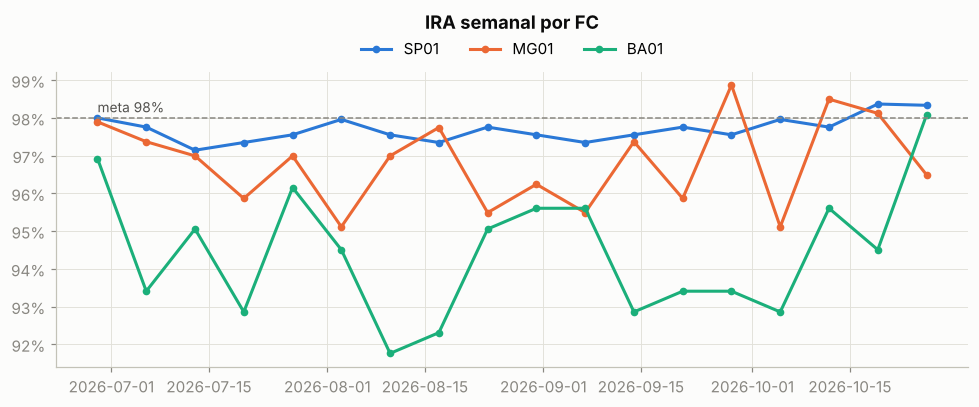

In [10]:
sem = q('''
SELECT date_trunc('week', data) AS semana, fc_id, 100 * avg((NOT div_final)::INT) AS ira
FROM cc GROUP BY ALL ORDER BY semana
''')
fig, ax = plt.subplots(figsize=(9, 3.8))
for fc in ["SP01", "MG01", "BA01"]:
    g = sem[sem["fc_id"] == fc]
    ax.plot(g["semana"], g["ira"], color=CORES_FC[fc], linewidth=2, marker="o", markersize=4, label=fc)
ax.axhline(98, color="#898781", linestyle="--", linewidth=1)
ax.text(sem["semana"].min(), 98.15, "meta 98%", color="#52514e", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("IRA semanal por FC", pad=28)
legenda_topo(ax)
plt.tight_layout(); plt.show()

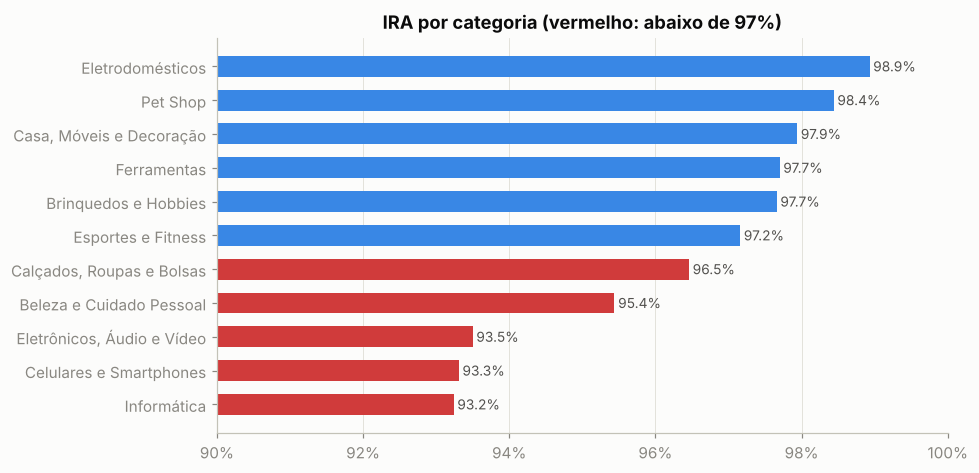

,categoria,contagens,ira_pct,divergencia_liquida_rs
0,Informática,829,93.24,"-42,203.56"
1,Celulares e Smartphones,673,93.31,"-3,126.63"
2,"Eletrônicos, Áudio e Vídeo",1000,93.50,"-21,712.33"
3,Beleza e Cuidado Pessoal,1228,95.44,"-1,654.76"
4,"Calçados, Roupas e Bolsas",2404,96.46,"-4,779.01"
5,Esportes e Fitness,1304,97.16,"-9,987.73"
6,Brinquedos e Hobbies,2987,97.66,"-1,235.14"
7,Ferramentas,1346,97.70,"-8,156.42"
8,"Casa, Móveis e Decoração",2812,97.94,"-12,031.57"
9,Pet Shop,1151,98.44,"-1,223.31"


In [11]:
ira_cat = q('''
SELECT categoria, count(*) AS contagens,
       round(100 * avg((NOT div_final)::INT), 2) AS ira_pct,
       round(sum(dif * preco_venda), 2) AS divergencia_liquida_rs
FROM cc GROUP BY 1 ORDER BY ira_pct
''')
fig, ax = plt.subplots(figsize=(9, 4.4))
cores = ["#d03b3b" if v < 97 else "#3987e5" for v in ira_cat["ira_pct"]]
ax.barh(ira_cat["categoria"], ira_cat["ira_pct"], color=cores, height=0.62)
for i, v in enumerate(ira_cat["ira_pct"]):
    ax.text(v + 0.05, i, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlim(90, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("IRA por categoria (vermelho: abaixo de 97%)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
ira_cat

## A2. Perdas de inventário (shrinkage)

Todo ajuste no saldo do WMS precisa de motivo. Ajustes negativos são perda para a operação (o FC responde pelo estoque do seller sob sua custódia).

| Métrica | Fórmula |
|---|---|
| **Perda líquida (R\$)** | $\sum_{ajustes} q_{ajuste} \cdot preço$ |
| **Shrinkage %** | $\dfrac{\lvert \text{perda líquida} \rvert}{\text{valor expedido no período}}$ |
| **Perda por motivo** | perda líquida agrupada por motivo (contagem cíclica, avaria interna, extravio, vencimento) |

In [12]:
q('''
WITH aj AS (
    SELECT a.fc_id, a.motivo, a.qtd_ajuste * s.preco_venda AS valor
    FROM ajustes a JOIN skus s USING (inventory_id)
),
exp AS (
    SELECT p.fc_id, sum(p.quantidade * s.preco_venda) AS valor_expedido
    FROM pedidos p JOIN skus s USING (inventory_id) WHERE p.status = 'EXPEDIDO' GROUP BY 1
)
SELECT aj.fc_id,
       round(sum(valor) FILTER (WHERE motivo = 'CONTAGEM_CICLICA'), 2) AS contagem_ciclica_rs,
       round(sum(valor) FILTER (WHERE motivo = 'AVARIA_INTERNA'), 2) AS avaria_interna_rs,
       round(sum(valor) FILTER (WHERE motivo = 'EXTRAVIO'), 2) AS extravio_rs,
       round(sum(valor) FILTER (WHERE motivo = 'VENCIMENTO'), 2) AS vencimento_rs,
       round(sum(valor), 2) AS perda_liquida_rs,
       round(any_value(e.valor_expedido), 2) AS valor_expedido_rs,
       round(100 * abs(sum(valor)) / any_value(e.valor_expedido), 3) AS shrinkage_pct
FROM aj JOIN exp e USING (fc_id)
GROUP BY 1 ORDER BY shrinkage_pct DESC
''')

,fc_id,contagem_ciclica_rs,avaria_interna_rs,extravio_rs,vencimento_rs,perda_liquida_rs,valor_expedido_rs,shrinkage_pct
0,BA01,"-36,600.71","-55,622.28","-20,702.71","-13,244.19","-126,169.89","34,123,268.16",0.37
1,MG01,"-40,281.02","-48,534.06","-9,295.30","-5,855.33","-103,965.71","39,935,884.25",0.26
2,SP01,"-39,740.80","-168,415.39","-31,886.39","-17,346.50","-257,389.08","109,311,906.81",0.23


## A3. Aging (idade do estoque)

Estoque parado ocupa endereço que poderia receber produto de giro e encarece a operação. Em fulfillment, a longa permanência costuma gerar cobrança de armazenagem para o seller, então o aging também é um alerta comercial.

$$\text{idade do lote} = \text{data de referência} - \text{data de entrada do lote}$$

$$\%\ \text{estoque envelhecido} = \frac{\sum_{\text{lotes com idade} > 90\,d} q \cdot preço}{\sum q \cdot preço}$$

In [13]:
con.execute(f'''
CREATE OR REPLACE TABLE aging AS
SELECT p.*, s.categoria, s.seller_id, s.preco_venda, p.quantidade * s.preco_venda AS valor,
       DATE '{DATA_REF}' - p.data_entrada_lote AS idade_dias,
       CASE WHEN idade_dias <= 30 THEN '0-30' WHEN idade_dias <= 60 THEN '31-60' WHEN idade_dias <= 90 THEN '61-90'
            WHEN idade_dias <= 180 THEN '91-180' ELSE '180+' END AS faixa
FROM posicao p JOIN skus s USING (inventory_id)
''')
ag = q('''
SELECT fc_id, faixa, sum(quantidade) AS unidades, sum(valor) AS valor
FROM aging GROUP BY ALL
''')
pv = ag.pivot_table(index="fc_id", columns="faixa", values="valor", aggfunc="sum").fillna(0)
faixas = ["0-30", "31-60", "61-90", "91-180", "180+"]
pv = pv[faixas]
pct = pv.div(pv.sum(axis=1), axis=0) * 100
pct.round(1)

faixa,0-30,31-60,61-90,91-180,180+
fc_id,,,,,
BA01,56.80,18.00,9.00,6.90,9.20
MG01,41.20,24.90,7.50,20.80,5.60
SP01,63.40,14.00,9.10,8.30,5.20


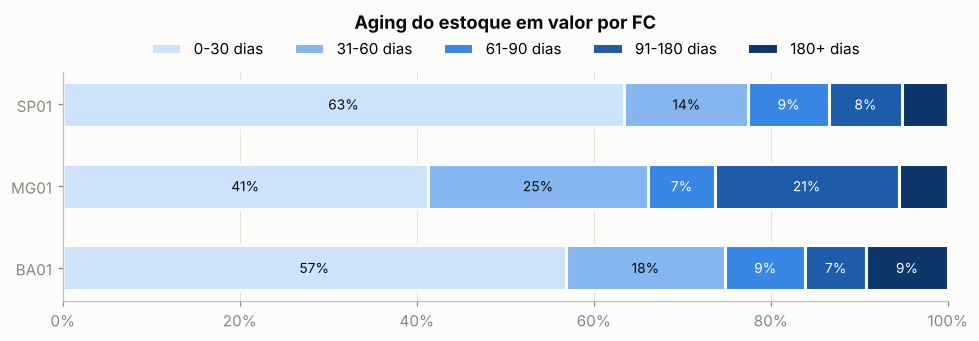

In [14]:
cores_aging = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
fig, ax = plt.subplots(figsize=(9, 3.2))
esq = pd.Series(0.0, index=pct.index)
for fx, cor in zip(faixas, cores_aging):
    ax.barh(pct.index, pct[fx], left=esq, color=cor, height=0.55, label=f"{fx} dias", edgecolor="#fcfcfb", linewidth=2)
    for i, (l, v) in enumerate(zip(esq, pct[fx])):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="#ffffff" if fx in ("61-90", "91-180", "180+") else "#0b0b0b")
    esq += pct[fx]
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.set_title("Aging do estoque em valor por FC", pad=28)
ax.grid(axis="y", visible=False)
legenda_topo(ax, ncol=5)
plt.tight_layout(); plt.show()

In [15]:
q('''
SELECT seller_id, count(DISTINCT inventory_id) AS skus, sum(quantidade) AS unidades_180_mais,
       round(sum(valor), 2) AS valor_180_mais
FROM aging WHERE faixa = '180+'
GROUP BY 1 ORDER BY valor_180_mais DESC LIMIT 10
''')

,seller_id,skus,unidades_180_mais,valor_180_mais
0,SL100046,56,888.00,"222,304.26"
1,SL100119,2,284.00,"222,255.60"
2,SL100299,31,553.00,"192,248.64"
3,SL100081,3,108.00,"139,762.30"
4,SL100226,6,89.00,"131,133.56"
5,SL100048,1,70.00,"115,862.60"
6,SL100354,16,325.00,"93,218.83"
7,SL100440,2,44.00,"84,003.26"
8,SL100510,2,37.00,"80,389.06"
9,SL100098,1,253.00,"78,723.48"


## A4. Cobertura, giro e sell-through

| Métrica | Fórmula |
|---|---|
| **Cobertura (DOH — days on hand)** | $\dfrac{\text{estoque atual}}{\text{venda média diária (últimos 30 dias)}}$ |
| **Giro anualizado (aprox.)** | $\dfrac{\text{unidades expedidas em 30 dias} \times 12}{\text{estoque atual}}$ |
| **Sell-through 30d** | $\dfrac{\text{expedido em 30 dias}}{\text{expedido em 30 dias} + \text{estoque atual}}$ |

O giro aqui é uma aproximação porque a extração traz apenas a foto final do estoque, e não o estoque médio do período.

In [16]:
q(f'''
WITH est AS (SELECT inventory_id, sum(quantidade) AS estoque FROM posicao GROUP BY 1),
vd AS (
    SELECT inventory_id, sum(quantidade) AS exp_30d FROM pedidos
    WHERE status = 'EXPEDIDO' AND dt_expedicao::DATE > DATE '{DATA_REF}' - 30 GROUP BY 1
)
SELECT s.categoria,
       sum(coalesce(e.estoque, 0)) AS estoque_unid,
       sum(coalesce(v.exp_30d, 0)) AS expedido_30d,
       round(sum(coalesce(e.estoque, 0)) / nullif(sum(coalesce(v.exp_30d, 0)) / 30, 0), 1) AS doh_dias,
       round(sum(coalesce(v.exp_30d, 0)) * 12 / nullif(sum(coalesce(e.estoque, 0)), 0), 1) AS giro_anual_aprox,
       round(100 * sum(coalesce(v.exp_30d, 0)) / nullif(sum(coalesce(v.exp_30d, 0)) + sum(coalesce(e.estoque, 0)), 0), 1) AS sell_through_30d_pct
FROM skus s LEFT JOIN est e USING (inventory_id) LEFT JOIN vd v USING (inventory_id)
GROUP BY 1 ORDER BY doh_dias DESC
''')

,categoria,estoque_unid,expedido_30d,doh_dias,giro_anual_aprox,sell_through_30d_pct
0,Eletrodomésticos,"4,108.00","2,678.00",46.00,7.80,39.50
1,Informática,"13,453.00","9,758.00",41.40,8.70,42.00
2,Pet Shop,"11,235.00","8,727.00",38.60,9.30,43.70
3,Celulares e Smartphones,"10,540.00","8,481.00",37.30,9.70,44.60
4,"Calçados, Roupas e Bolsas","15,188.00","12,332.00",36.90,9.70,44.80
5,Ferramentas,"8,542.00","6,975.00",36.70,9.80,45.00
6,Beleza e Cuidado Pessoal,"10,802.00","9,130.00",35.50,10.10,45.80
7,Brinquedos e Hobbies,"16,246.00","14,104.00",34.60,10.40,46.50
8,"Casa, Móveis e Decoração","27,709.00","25,059.00",33.20,10.90,47.50
9,Esportes e Fitness,"8,914.00","8,510.00",31.40,11.50,48.80


## A5. Ocupação de capacidade

$$\text{ocupação} = \frac{\text{endereços ocupados}}{\text{capacidade de endereços}}$$

Acima de ~85–90% a operação perde eficiência: a armazenagem demora mais para achar posição livre, cresce o estoque "provisório" em área de pulmão e piora a acuracidade.

In [17]:
q('''
SELECT f.fc_id, f.nome_fc, f.capacidade_posicoes,
       count(DISTINCT p.endereco) AS enderecos_ocupados,
       round(100.0 * count(DISTINCT p.endereco) / f.capacidade_posicoes, 1) AS ocupacao_pct,
       count(DISTINCT p.endereco) FILTER (WHERE a.faixa IN ('91-180', '180+')) AS enderecos_com_lote_90d_mais
FROM fcs f JOIN posicao p USING (fc_id)
LEFT JOIN aging a ON a.endereco = p.endereco AND a.inventory_id = p.inventory_id AND a.data_entrada_lote = p.data_entrada_lote
GROUP BY f.fc_id, f.nome_fc, f.capacidade_posicoes ORDER BY ocupacao_pct DESC
''')

,fc_id,nome_fc,capacidade_posicoes,enderecos_ocupados,ocupacao_pct,enderecos_com_lote_90d_mais
0,SP01,FC São Paulo 01,2800,2546,90.90,492
1,MG01,FC Minas Gerais 01,1540,1294,84.00,289
2,BA01,FC Bahia 01,1180,864,73.20,177


## A6. Ruptura operacional: a conta da falta de acuracidade

Quando o WMS mostra saldo que não existe fisicamente ("estoque fantasma"), o pedido é aceito, o separador não encontra o item e o pedido é cancelado por falta.

$$\text{taxa de cancelamento por falta} = \frac{\text{pedidos cancelados por falta de estoque}}{\text{pedidos recebidos}}$$

In [18]:
rup = q('''
WITH c AS (
    SELECT fc_id, count(*) AS pedidos,
           count(*) FILTER (WHERE status = 'CANCELADO_FALTA_ESTOQUE') AS cancel_falta
    FROM pedidos GROUP BY 1
)
SELECT c.fc_id, c.pedidos, c.cancel_falta,
       round(100.0 * c.cancel_falta / c.pedidos, 2) AS cancel_falta_pct,
       i.ira_endereco_pct
FROM c JOIN (SELECT fc_id, round(100 * avg((NOT div_final)::INT), 2) AS ira_endereco_pct FROM cc GROUP BY 1) i USING (fc_id)
ORDER BY cancel_falta_pct
''')
rup

,fc_id,pedidos,cancel_falta,cancel_falta_pct,ira_endereco_pct
0,SP01,145470,557,0.38,97.69
1,MG01,73702,480,0.65,96.79
2,BA01,45151,594,1.32,94.37


---
# Parte B — Operação diária

## B1. Recebimento (inbound)

| Métrica | Fórmula | Leitura |
|---|---|---|
| **Dock-to-stock** | $t_{\text{fim armazenagem}} - t_{\text{chegada}}$ | Tempo até o produto ficar disponível para venda |
| **Pontualidade do agendamento** | $\dfrac{\text{ASNs com chegada} \le \text{agendamento} + 30\,min}{\text{ASNs}}$ | Disciplina dos sellers/transportadoras |
| **Divergência de ASN** | $\dfrac{\sum \lvert q_{recebida} - q_{declarada} \rvert}{\sum q_{declarada}}$ | Erro do seller no aviso de envio |
| **Taxa de avaria no recebimento** | $\dfrac{\sum q_{avariada}}{\sum q_{recebida}}$ | Qualidade da embalagem de origem |

Usamos P50 (mediana) e P90 em vez de média para tempos: o P90 mostra a cauda que o seller sente.

In [19]:
inb = q('''
WITH asn AS (
    SELECT asn_id, fc_id, any_value(dt_agendamento) AS ag, any_value(dt_chegada) AS ch,
           any_value(dt_fim_conferencia) AS conf, any_value(dt_fim_armazenagem) AS arm
    FROM recebimentos GROUP BY ALL
),
linhas AS (
    SELECT fc_id, sum(abs(qtd_recebida - qtd_declarada)) AS dif, sum(qtd_declarada) AS dec,
           sum(qtd_avariada) AS av, sum(qtd_recebida) AS rec,
           avg((qtd_recebida <> qtd_declarada)::INT) AS linhas_div
    FROM recebimentos GROUP BY 1
)
SELECT a.fc_id, count(*) AS asns,
       round(median(epoch(arm - ch) / 3600), 1) AS dock_to_stock_p50_h,
       round(quantile_cont(epoch(arm - ch) / 3600, 0.9), 1) AS dock_to_stock_p90_h,
       round(median(epoch(conf - ch) / 3600), 1) AS conferencia_p50_h,
       round(100 * avg((ch <= ag + INTERVAL 30 MINUTE)::INT), 1) AS pontualidade_agend_pct,
       round(100 * any_value(l.dif) / any_value(l.dec), 2) AS divergencia_asn_pct,
       round(100 * any_value(l.linhas_div), 1) AS linhas_com_divergencia_pct,
       round(100 * any_value(l.av) / any_value(l.rec), 2) AS avaria_recebimento_pct
FROM asn a JOIN linhas l USING (fc_id)
GROUP BY 1 ORDER BY dock_to_stock_p50_h
''')
inb

,fc_id,asns,dock_to_stock_p50_h,dock_to_stock_p90_h,conferencia_p50_h,pontualidade_agend_pct,divergencia_asn_pct,linhas_com_divergencia_pct,avaria_recebimento_pct
0,MG01,753,9.20,18.90,2.20,86.20,0.37,5.10,0.30
1,SP01,1569,9.50,19.70,2.30,88.80,0.31,4.90,0.27
2,BA01,568,13.30,27.00,3.60,87.30,0.27,4.90,0.38


## B2. Expedição (outbound)

| Métrica | Fórmula | Leitura |
|---|---|---|
| **On-time shipping (OTS)** | $\dfrac{\text{pedidos expedidos até } t_{limite}}{\text{pedidos expedidos}}$ | Principal KPI do outbound; atraso aqui vira atraso de entrega |
| **Order cycle time** | $t_{expedição} - t_{pedido}$ | Do clique do cliente até a coleta pela transportadora |
| **Backlog** | pedidos recebidos e ainda não expedidos no fim do dia | Sinal de capacidade insuficiente |

Regra de corte (cut-off) desta operação: pedido feito até 13h precisa sair na coleta das 18h do mesmo dia; depois das 13h, até a coleta das 14h do dia seguinte. As transportadoras coletam às 10h, 14h, 18h e 22h.

In [20]:
q('''
SELECT fc_id,
       count(*) AS expedidos,
       round(100 * avg((dt_expedicao <= dt_limite_expedicao)::INT), 2) AS ots_pct,
       round(median(epoch(dt_expedicao - dt_pedido) / 3600), 1) AS cycle_time_p50_h,
       round(quantile_cont(epoch(dt_expedicao - dt_pedido) / 3600, 0.9), 1) AS cycle_time_p90_h,
       round(median(epoch(dt_fim_packing - dt_inicio_picking) / 60), 0) AS pick_pack_p50_min
FROM pedidos WHERE status = 'EXPEDIDO'
GROUP BY 1 ORDER BY ots_pct DESC
''')

,fc_id,expedidos,ots_pct,cycle_time_p50_h,cycle_time_p90_h,pick_pack_p50_min
0,SP01,143600,99.59,3.40,11.90,25.00
1,BA01,44195,98.82,3.90,12.30,26.00
2,MG01,72507,93.22,3.90,15.80,25.00


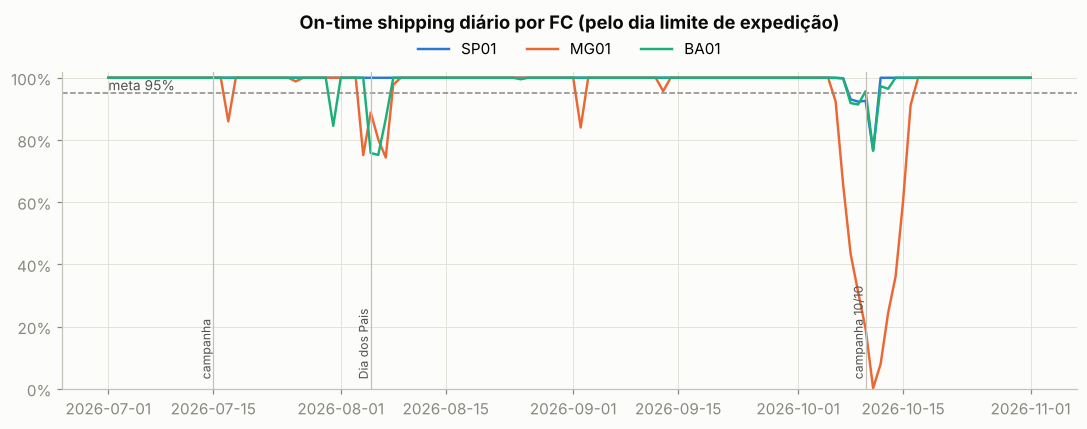

In [21]:
ots = q('''
SELECT dt_limite_expedicao::DATE AS dia, fc_id, 100 * avg((dt_expedicao <= dt_limite_expedicao)::INT) AS ots
FROM pedidos WHERE status = 'EXPEDIDO' GROUP BY ALL ORDER BY dia
''')
fig, ax = plt.subplots(figsize=(10, 4))
for fc in ["SP01", "MG01", "BA01"]:
    g = ots[ots["fc_id"] == fc]
    ax.plot(g["dia"], g["ots"], color=CORES_FC[fc], linewidth=1.6, label=fc)
ax.axhline(95, color="#898781", linestyle="--", linewidth=1)
ax.text(ots["dia"].min(), 96, "meta 95%", color="#52514e", fontsize=9)
for d, txt in [("2026-07-15", "campanha"), ("2026-08-05", "Dia dos Pais"), ("2026-10-10", "campanha 10/10")]:
    ax.axvline(pd.Timestamp(d), color="#c3c2b7", linewidth=0.8)
    ax.text(pd.Timestamp(d), 4, txt, rotation=90, fontsize=8, color="#52514e", ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 102)
ax.set_title("On-time shipping diário por FC (pelo dia limite de expedição)", pad=28)
legenda_topo(ax)
plt.tight_layout(); plt.show()

In [22]:
backlog = q('''
WITH dias AS (SELECT unnest(generate_series(DATE '2026-07-01', DATE '2026-10-31', INTERVAL 1 DAY))::DATE AS dia)
SELECT d.dia, p.fc_id,
       count(*) FILTER (WHERE p.dt_pedido < d.dia + INTERVAL 22 HOUR
                        AND (p.dt_expedicao IS NULL OR p.dt_expedicao > d.dia + INTERVAL 22 HOUR)
                        AND p.status IN ('EXPEDIDO', 'PENDENTE')) AS backlog_22h
FROM dias d JOIN pedidos p ON p.dt_pedido::DATE BETWEEN d.dia - 7 AND d.dia
GROUP BY ALL ORDER BY d.dia
''')
backlog.pivot_table(index="fc_id", values="backlog_22h", aggfunc=["mean", "max"]).round(0)

,mean,max
,backlog_22h,backlog_22h
fc_id,,
BA01,36.00,190
MG01,83.00,586
SP01,93.00,544


## B3. Produtividade (UPH)

$$\text{UPH} = \frac{\text{unidades processadas}}{\text{horas trabalhadas}} \qquad \text{aderência à meta} = \frac{\text{UPH real}}{\text{UPH meta}}$$

Metas de referência por processo (unidades/hora): recebimento 220, armazenagem 115, picking 90, packing 110, expedição 230.

In [23]:
METAS = {"RECEBIMENTO": 220, "ARMAZENAGEM": 115, "PICKING": 90, "PACKING": 110, "EXPEDICAO": 230}
con.execute("CREATE OR REPLACE TABLE metas AS SELECT * FROM (VALUES " +
            ", ".join(f"('{k}', {v})" for k, v in METAS.items()) + ") t(processo, uph_meta)")

uph = q('''
SELECT a.fc_id, a.processo, sum(a.unidades) AS unidades, round(sum(a.horas), 0) AS horas,
       round(sum(a.unidades) / sum(a.horas), 1) AS uph_real, any_value(m.uph_meta) AS uph_meta,
       round(100 * sum(a.unidades) / sum(a.horas) / any_value(m.uph_meta), 1) AS aderencia_pct
FROM apont a JOIN metas m USING (processo)
GROUP BY ALL ORDER BY a.processo, a.fc_id
''')
uph.pivot_table(index="processo", columns="fc_id", values="aderencia_pct").loc[list(METAS)]

fc_id,BA01,MG01,SP01
processo,,,
RECEBIMENTO,77.70,93.90,100.80
ARMAZENAGEM,77.90,94.50,99.90
PICKING,74.70,89.70,96.90
PACKING,78.50,90.60,97.30
EXPEDICAO,66.20,92.70,102.70


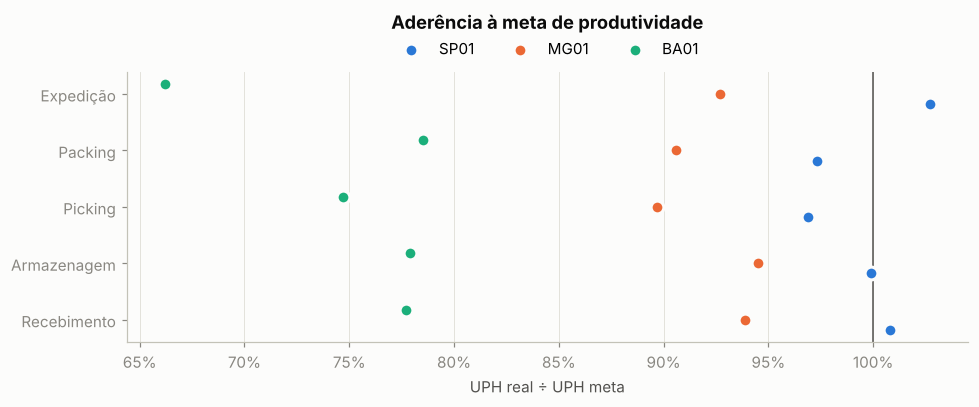

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.8))
procs = list(METAS)
for k, fc in enumerate(["SP01", "MG01", "BA01"]):
    g = uph[uph["fc_id"] == fc].set_index("processo").reindex(procs)
    ax.scatter(g["aderencia_pct"], [i + (k - 1) * 0.18 for i in range(len(procs))], s=70, color=CORES_FC[fc],
               label=fc, edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.axvline(100, color="#52514e", linewidth=1)
ax.set_yticks(range(len(procs)), ["Recebimento", "Armazenagem", "Picking", "Packing", "Expedição"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("UPH real ÷ UPH meta")
ax.set_title("Aderência à meta de produtividade", pad=28)
ax.grid(axis="y", visible=False)
legenda_topo(ax)
plt.tight_layout(); plt.show()

In [25]:
q('''
SELECT a.fc_id, a.turno, round(sum(a.unidades) / sum(a.horas), 1) AS uph_picking
FROM apont a WHERE processo = 'PICKING' GROUP BY ALL
''').pivot_table(index="fc_id", columns="turno", values="uph_picking")

turno,T1,T2
fc_id,,
BA01,69.20,65.20
MG01,82.90,78.40
SP01,89.70,84.60


## B4. Qualidade: acuracidade de separação e pedido perfeito

| Métrica | Fórmula |
|---|---|
| **Acuracidade de picking** | $1 - \dfrac{\text{pedidos com ocorrência de separação (item errado, faltante, quantidade)}}{\text{pedidos expedidos}}$ |
| **DPMO** | $\dfrac{\text{ocorrências}}{\text{pedidos expedidos}} \times 10^6$ |
| **Pedido perfeito (POR)** | $\dfrac{\text{pedidos expedidos no prazo e sem ocorrência}}{\text{pedidos válidos}}$ — pedidos válidos = todos, exceto cancelados pelo cliente |

O pedido perfeito junta prazo, qualidade e disponibilidade em um único número; uma falha em qualquer etapa derruba o pedido.

In [26]:
q('''
WITH base AS (
    SELECT p.*, o.tipo AS ocorrencia,
           o.tipo IN ('ITEM_ERRADO', 'ITEM_FALTANTE', 'QUANTIDADE_DIVERGENTE') AS erro_separacao
    FROM pedidos p LEFT JOIN ocorrencias o USING (order_id)
    WHERE p.status <> 'CANCELADO_CLIENTE'
)
SELECT fc_id,
       count(*) AS pedidos_validos,
       count(*) FILTER (WHERE status = 'EXPEDIDO') AS expedidos,
       count(ocorrencia) AS ocorrencias,
       round(100 * (1 - count(*) FILTER (WHERE erro_separacao) / count(*) FILTER (WHERE status = 'EXPEDIDO')), 3) AS acuracidade_picking_pct,
       round(1e6 * count(ocorrencia) / count(*) FILTER (WHERE status = 'EXPEDIDO'), 0) AS dpmo,
       round(100.0 * count(*) FILTER (WHERE status = 'EXPEDIDO' AND dt_expedicao <= dt_limite_expedicao AND ocorrencia IS NULL)
             / count(*), 2) AS pedido_perfeito_pct
FROM base GROUP BY 1 ORDER BY pedido_perfeito_pct DESC
''')

,fc_id,pedidos_validos,expedidos,ocorrencias,acuracidade_picking_pct,dpmo,pedido_perfeito_pct
0,SP01,144308,143600,311,99.81,"2,166.00",98.89
1,BA01,44823,44195,235,99.53,"5,317.00",96.92
2,MG01,73048,72507,189,99.78,"2,607.00",92.29


In [27]:
q('''
SELECT p.fc_id, CASE WHEN hour(p.dt_inicio_picking) < 14 THEN 'T1' ELSE 'T2' END AS turno,
       round(1e6 * count(o.order_id) / count(*), 0) AS dpmo
FROM pedidos p LEFT JOIN ocorrencias o USING (order_id)
WHERE p.status = 'EXPEDIDO' GROUP BY ALL
''').pivot_table(index="fc_id", columns="turno", values="dpmo")

turno,T1,T2
fc_id,,
BA01,"4,220.00","6,506.00"
MG01,"1,908.00","3,364.00"
SP01,"1,833.00","2,532.00"


## B5. Scorecard diário

Rotina da manhã do analista: um quadro por FC com os indicadores do dia anterior contra a meta. A função abaixo gera o quadro para qualquer data.

In [28]:
def scorecard(dia):
    return q(f'''
    WITH ped AS (
        SELECT fc_id,
               100 * avg((dt_expedicao <= dt_limite_expedicao)::INT) FILTER (WHERE status = 'EXPEDIDO') AS ots,
               100.0 * count(*) FILTER (WHERE status = 'CANCELADO_FALTA_ESTOQUE') / count(*) AS cancel_falta
        FROM pedidos WHERE dt_limite_expedicao::DATE = DATE '{dia}' GROUP BY 1
    ),
    pk AS (
        SELECT fc_id, sum(unidades) FILTER (WHERE processo = 'PICKING') / sum(horas) FILTER (WHERE processo = 'PICKING') AS uph_picking,
               sum(unidades) FILTER (WHERE processo = 'PICKING') AS unid_separadas
        FROM apont WHERE data = DATE '{dia}' GROUP BY 1
    ),
    ira AS (SELECT fc_id, 100 * avg((NOT div_final)::INT) AS ira FROM cc WHERE data = DATE '{dia}' GROUP BY 1),
    d2s AS (
        SELECT fc_id, median(epoch(dt_fim_armazenagem - dt_chegada) / 3600) AS dock_to_stock_h
        FROM recebimentos WHERE dt_chegada::DATE = DATE '{dia}' GROUP BY 1
    )
    SELECT fc_id, unid_separadas,
           round(ots, 1) AS ots_pct, CASE WHEN ots >= 95 THEN 'ok' ELSE 'abaixo' END AS ots_status,
           round(uph_picking, 1) AS uph_picking, CASE WHEN uph_picking >= 90 THEN 'ok' ELSE 'abaixo' END AS uph_status,
           round(ira, 1) AS ira_pct, CASE WHEN ira >= 98 THEN 'ok' ELSE 'abaixo' END AS ira_status,
           round(cancel_falta, 2) AS cancel_falta_pct, CASE WHEN cancel_falta <= 0.5 THEN 'ok' ELSE 'acima' END AS cancel_status,
           round(dock_to_stock_h, 1) AS dock_to_stock_h, CASE WHEN dock_to_stock_h <= 24 THEN 'ok' ELSE 'acima' END AS d2s_status
    FROM ped LEFT JOIN pk USING (fc_id) LEFT JOIN ira USING (fc_id) LEFT JOIN d2s USING (fc_id)
    ORDER BY fc_id
    ''')

scorecard("2026-10-30")

,fc_id,unid_separadas,ots_pct,ots_status,uph_picking,uph_status,ira_pct,ira_status,cancel_falta_pct,cancel_status,dock_to_stock_h,d2s_status
0,BA01,628.00,100.00,ok,66.40,abaixo,100.00,ok,0.51,acima,26.10,acima
1,MG01,949.00,100.00,ok,82.70,abaixo,97.40,abaixo,0.69,acima,6.90,ok
2,SP01,"2,107.00",100.00,ok,88.70,abaixo,98.60,ok,0.16,ok,11.90,ok


In [29]:
scorecard("2026-10-10")

,fc_id,unid_separadas,ots_pct,ots_status,uph_picking,uph_status,ira_pct,ira_status,cancel_falta_pct,cancel_status,dock_to_stock_h,d2s_status
0,BA01,723.00,95.70,ok,61.70,abaixo,100.00,ok,0.70,acima,18.70,ok
1,MG01,"1,090.00",19.20,abaixo,72.70,abaixo,97.40,abaixo,0.58,acima,15.00,ok
2,SP01,"2,334.00",92.60,abaixo,76.20,abaixo,97.10,abaixo,0.51,acima,13.80,ok


## Conclusões

**Qualidade de dados.** A extração do WMS tinha datas em dois formatos, status escritos de várias formas, códigos de FC fora do padrão e pedidos duplicados. Sem tratamento, só **23,7%** dos turnos de picking batiam com os apontamentos; depois, **100%**.

### Inventário
- **Acuracidade:** nenhum FC atinge a meta de 98% de IRA (SP 97,7%, MG 96,8%, BA 94,4%). As piores categorias são itens pequenos e caros (Informática, Celulares, Eletrônicos ~93%), que pedem endereçamento em área controlada e contagem mais frequente.
- **Recontagem vale a pena:** cerca de 1 em cada 3 divergências da 1ª contagem era erro de contagem. Sem a recontagem, o sistema seria ajustado errado.
- **Perdas:** R$ 487 mil em 4 meses, ou 0,23% a 0,37% do valor expedido. **Avaria interna** é o maior motivo (manuseio dentro do FC), à frente das divergências de contagem.
- **Ruptura causada por acuracidade:** o cancelamento por falta acompanha o IRA. BA, com o pior IRA, cancela **1,32%** dos pedidos, 3,5× mais que SP.
- **Aging e espaço:** SP está com **91% de ocupação**, acima do limite saudável, com 492 endereços contendo lotes com mais de 90 dias. MG tem **26% do valor** com mais de 90 dias. Acionar os sellers com estoque acima de 180 dias libera posição para produto de giro.

### Operação diária
- **Recebimento:** BA leva 13 h (P50) e 27 h (P90) do caminhão ao estoque disponível, contra 9 h em SP/MG. O gargalo é a conferência.
- **Expedição:** OTS de 99,6% (SP), 98,8% (BA) e **93,2% (MG)**. MG não absorveu o pico da campanha 10/10: o backlog se acumulou por uma semana e o OTS caiu a praticamente zero em 11/10.
- **Produtividade:** BA opera entre 66% e 78% da meta em todos os processos. O turno 2 é menos produtivo e erra mais em todos os FCs.
- **Qualidade:** o DPMO de BA (5,3 mil) é mais que o dobro do de SP. O pedido perfeito é de 98,9% em SP, 96,9% em BA e 92,3% em MG (puxado pelo atraso).

### Recomendações
1. **BA:** plano de acuracidade (contagem diária de itens A e de alto valor, causa raiz por operador e endereço), reforço na conferência do inbound e treinamento do turno 2.
2. **MG:** planejamento de capacidade para campanhas, com headcount temporário e horas extras definidos por previsão de volume, e não depois que o backlog aparece.
3. **SP:** liberar posições com lotes envelhecidos (campanha de saída ou cobrança de longa permanência) antes do pico de fim de ano.
4. **Rede:** atacar avaria interna (embalagem, altura de armazenagem, manuseio) e colocar o scorecard diário (B5) na reunião de abertura de turno.